# Chapter 11 — Matplotlib: Foundational Data Visualization

Matplotlib is the core plotting library. Learn figures, axes, plot types, labels, scales, legends, layout, and export controls.

## Prerequisites
NumPy/Pandas basics; install Matplotlib.

## Learning goals
- Distinguish Figure and Axes objects.
- Create line, bar, scatter, histogram, and box plots.
- Control labels, scales, legends, grids, and layouts.
- Export charts with readable dimensions and resolution.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Guided learning path

Work from top to bottom. Each step states the purpose, explains the API choice, and provides a complete code cell. Modify parameters and predict the output before running it.

### Step 1 — Guided 1 — Compare regional revenue

Aggregate first, then plot one value per region.

Data directory: /mnt/data/python_data_analysis_book/data


/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Step_by_Step_Tutorial.ipynb:8: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



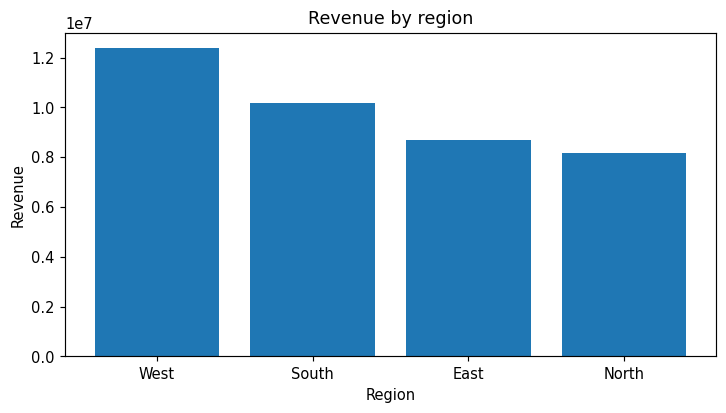

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd, matplotlib.pyplot as plt
sales=pd.read_csv(DATA/"sales.csv"); region=sales.groupby("region").revenue.sum().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(8,4)); ax.bar(region.index,region.values); ax.set(title="Revenue by region",xlabel="Region",ylabel="Revenue"); plt.show()

### Step 2 — Guided 2 — Examine a time trend

A line chart connects observations, so sort by date and aggregate to a consistent time grain.

/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Step_by_Step_Tutorial.ipynb:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



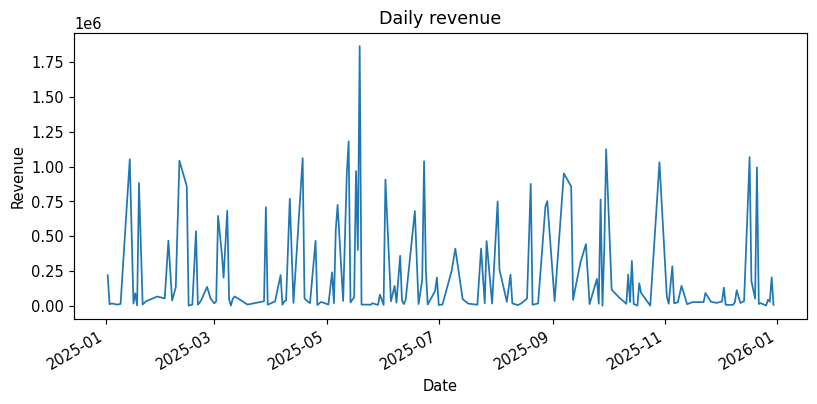

In [3]:
sales["order_date"]=pd.to_datetime(sales.order_date); daily=sales.groupby("order_date").revenue.sum().sort_index()
fig,ax=plt.subplots(figsize=(9,4)); ax.plot(daily.index,daily.values,lw=1.2); ax.set(xlabel="Date",ylabel="Revenue",title="Daily revenue"); fig.autofmt_xdate(); plt.show()

### Step 3 — Guided 3 — Inspect profit distribution

Histograms depend on bin width; compare with a box plot or quantiles.

/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Step_by_Step_Tutorial.ipynb:1: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



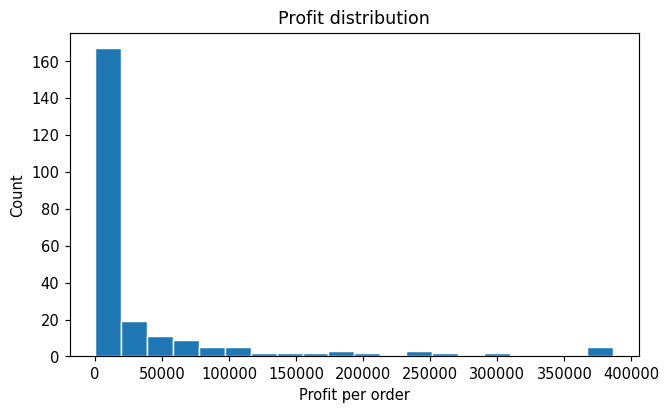

In [4]:
fig,ax=plt.subplots(figsize=(7,4)); ax.hist(sales.profit,bins=20,edgecolor="white"); ax.set(xlabel="Profit per order",ylabel="Count",title="Profit distribution"); plt.show()

### Step 4 — Guided 4 — Export the final chart

`savefig` accepts a filename, DPI for raster output, and a tight bounding box to reduce clipping.

In [5]:
fig.savefig("profit_distribution.png",dpi=160,bbox_inches="tight"); print("Saved plot")

Saved plot


## Tutorial checkpoint

1. What was the input data type?
2. What did the function or method return?
3. Which argument most changed the result?
4. What edge case should be tested before using this in production?